<a href="https://colab.research.google.com/github/simichakravarty16/walmart-hurricane-project/blob/main/notebooks/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### 1. Import Libraries

In [1]:
import pandas as pd
import os
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests, time
import matplotlib.dates as mdates

### 2. Define Decision log



In [2]:
DECISIONS = []

def log(dataset, step, decision, rows_affected):
    DECISIONS.append({'dataset': dataset, 'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{dataset}] [{step}] {decision} ({rows_affected} row(s))')

### 3. Data Setup

In [3]:
# Set data directory
DATA_DIR = '/content'

# Define data loading function
def load_data(filename):
  return pd.read_csv(os.path.join(DATA_DIR, filename))

### 4. Data Cleaning

#### 4.1 Walmart Transactions

In [4]:
# Load walmart transactions dataset
transactions = load_data('walmart_transactions.csv')
transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [5]:
# Count number of rows in the dataset
raw_rows = len(transactions)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
transactions.info()

starting with 25562 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  25562 non-null  object
 1   store_id        25562 non-null  object
 2   timestamp       24676 non-null  object
 3   sku             25562 non-null  object
 4   product_name    25562 non-null  object
 5   category        25562 non-null  object
 6   quantity        25562 non-null  int64 
 7   unit_price      25562 non-null  object
dtypes: int64(1), object(7)
memory usage: 1.6+ MB


In [6]:
transactions.describe()

,quantity
count,25562.000000
mean,1.932634
std,1.086926
min,-5.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,6.000000


In [7]:
print('shape:', transactions.shape)
print()
print('dtypes:', transactions.dtypes)
print()
print('nulls:', transactions.isnull().sum())
print()
print('duplicates:', transactions.duplicated().sum())

shape: (25562, 8)

dtypes: transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object

nulls: transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

duplicates: 30


In [8]:
# Inspect unique SKUs, product names, and categories
print('unique SKUs:', transactions['sku'].nunique())
print('unique SKUs:', transactions['sku'].unique())
print()
print('unique product names:', transactions['product_name'].nunique())
print()
print('unique categories:', transactions['category'].nunique())

unique SKUs: 45
unique SKUs: ['PNUTBTR-16' 'CNSOUP-01' 'TOILETPAPER12' 'ROKU-STD' 'BEER-24'
 'CHIPVARIETY' 'TARP-HD' 'PAPERTOWEL6' 'CANDLE-EMRG' 'CARDS-01' 'CHIPS-VP'
 'HDTARP-01' 'WHITEBREAD' 'PORTCHARGER' 'PTOWEL-6' 'FIRSTAID-KIT'
 'PT_STRAWBERRY' 'LTBEER24' 'FLASH-01' 'PB-16' 'SKU#459812' 'BATT_AA_4PK'
 'BFORM-01' 'WTR-24' 'STREAM-01' 'BATT-100' 'CNDL-EM' 'TP-12' 'PT-12'
 'BABYFORMULA' 'DIAP-S3' 'POPTART-STRAW' 'DIAPERS-3' 'SOUP-CAN'
 'PLAYCARD-STD' 'WATER24PK' 'CHRG-PORT' 'BG-MONO' 'MONOPOLY-01' 'BAT-AA4'
 'LED-FLASH' 'FAID-01' 'BREAD-WH' 'GAME-MONO' 'WTR_24PK']

unique product names: 63

unique categories: 37


Problems:
1. There are 30 duplicate rows in the dataset.
2. There are 886 nulls in the `timestamp` column. Missing values are represented in several ways, including empty strings, `NULL`, `N/A`, `NaN`, and `nan`.
3. Dates and times are in different formats in the `timestamp` column.
4. The same products appear under different SKUs and product names.
5. There are inconsistencies in capitalization and spacing.
6. The same products have different category names.
7. The `unit_price` column is stored as `str` instead of `float`, and some values  contains `$` signs.
8. There are negative quantities in the `quantity` column.  
9. The `store_id` column does not consistently follow the `FL-#` format.

In [9]:
# Transform: Types and Duplicates
def transform_types(df):
    out = df.copy()

    # Drop duplicates
    before = len(out)
    out = out.drop_duplicates()
    removed = before - len(out)
    log('walmart_transactions', 'remove duplicates', 'Removed duplicate rows', removed)

    # Normalize timestamps
    out['timestamp'] = pd.to_datetime(out['timestamp'], errors='coerce', format='mixed')
    missing = out['timestamp'].isna().sum()
    log('walmart_transactions', 'clean timestamp', 'Converted timestamps to datetime and kept missing values as NaT', missing)

    # Create date column for joining with daily weather data
    out['date'] = out['timestamp'].dt.normalize()
    log('walmart_transactions', 'create date column', 'Extracted calendar date from timestamp for weather merge', out['date'].notna().sum())

    # Convert unit_price to float (no $ sign)
    out['unit_price'] = (out['unit_price'].astype(str)
                         .str.replace('$', '', regex=False) # remove $ sign
                         .str.strip().astype(float))    # change unit prices to float
    affected_price = len(out)
    log('walmart_transactions', 'clean unit_price', 'Removed $ sign and converted unit_price to float', affected_price)

    # Clean quantity
    before = len(out)
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    # Decision: drop the unparseable quantity and the return. We are measuring
    # units that left the shelf ahead of the hurricane, so a return is not that.
    out = out[out['quantity'].notna() & (out['quantity'] > 0)].copy()
    out['quantity'] = out['quantity'].astype(int)
    removed_quantity = before - len(out)
    log('walmart_transactions', 'clean quantity', 'Removed negative quantities (returns)', removed_quantity)

    # Standardize store_id
    old_id = out['store_id'].copy()
    out['store_id'] = out['store_id'].astype(str).str.upper().str.strip().str.replace(r'^FL[\s_-]*(\d+)$', r'FL-\1', regex=True)
    affected_id = (old_id != out['store_id']).sum()
    log('walmart_transactions', 'clean store_id', 'Standardized store IDs to FL-# format', affected_id)

    return out

In [10]:
# Transform: consolidate SKUs, product names, and categories

# Consolidate SKUs
SKU_MAP = {
    'BATT_AA_4PK': 'BAT-AA4',
    'BATT-100': 'BAT-AA4',
    'BEER-24': 'LTBEER24',
    'BABYFORMULA': 'BFORM-01',
    'BG-MONO': 'BG-MONO-01',
    'MONOPOLY-01': 'BG-MONO-01',
    'GAME-MONO': 'BG-MONO-01',
    'BREAD-WH': 'WHITEBREAD',
    'CNDL-EM': 'CANDLE-EMRG',
    'PLAYCARD-STD': 'CARDS-01',
    'CHIPVARIETY': 'CHIPS-VP',
    'PORTCHARGER': 'CHRG-PORT',
    'SOUP-CAN': 'CNSOUP-01',
    'DIAPERS-3': 'DIAP-S3',
    'FIRSTAID-KIT': 'FAID-01',
    'LED-FLASH': 'FLASH-01',
    'TARP-HD': 'HDTARP-01',
    'PAPERTOWEL6': 'PTOWEL6',
    'PTOWEL-6': 'PTOWEL6',
    'TOILETPAPER12': 'TOILETPAPER-12',
    'TP-12': 'TOILETPAPER-12',
    'PB-16': 'PNUTBTR-16',
    'PT-12': 'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'PT_STRAWBERRY': 'POPTART-STRAW',
    'ROKU-STD': 'ROKU-STREAM',
    'STREAM-01': 'ROKU-STREAM',
    'WATER24PK': 'WATER-24',
    'WTR_24PK': 'WATER-24',
    'WTR-24': 'WATER-24'
}

# Standardize product names
PRODUCT_MAP = {
    'BAT-AA4': 'Batteries AA 4PK',
    'LTBEER24': 'Light Beer 24PK',
    'BFORM-01': 'Baby Formula',
    'BG-MONO-01': 'Monopoly Board Game',
    'WHITEBREAD': 'White Bread',
    'CANDLE-EMRG': 'Emergency Candle',
    'CARDS-01': 'Playing Cards',
    'CHIPS-VP': 'Chip Variety Pack',
    'CHRG-PORT': 'Portable Phone Charger',
    'CNSOUP-01': 'Canned Soup',
    'DIAP-S3': 'Diapers Size 3',
    'FAID-01': 'First Aid Kit',
    'FLASH-01': 'LED Flashlight',
    'HDTARP-01': 'Heavy Duty Tarp',
    'PTOWEL6': 'Paper Towels 6PK',
    'TOILETPAPER-12': 'Toilet Paper 12PK',
    'PNUTBTR-16': 'Peanut Butter 16oz',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'ROKU-STREAM': 'Roku Streaming Stick',
    'WATER-24': 'Bottled Water 24PK'
}

# Standardize categories
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Groceries': 'Grocery',
    'Games & Entertainment': 'Entertainment',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

def consolidate_transactions(df):
    out = df.copy()

    # Consolidate SKUs
    old_sku = out['sku'].copy()
    out['sku'] = out['sku'].map(SKU_MAP).fillna(out['sku'])
    affected_sku = (old_sku != out['sku']).sum()
    log('walmart_transactions', 'clean sku', 'Consolidated SKUs so the same products share the same SKU', affected_sku)

    # Standardize product names
    old_name = out['product_name'].copy()
    out['product_name'] = out['sku'].map(PRODUCT_MAP).fillna(out['product_name'])
    affected_name = (old_name != out['product_name']).sum()
    log('walmart_transactions', 'clean product_name', 'Standardized product names based on SKUs for consistency', affected_name)

    # Standardize categories
    old_category = out['category'].copy()
    out['category'] = out['category'].str.strip().str.title().replace(CATEGORY_MAP)
    affected_category = (old_category != out['category']).sum()
    log('walmart_transactions', 'clean category', 'Standardized category names, capitalization, and spacing', affected_category)

    return out

In [11]:
def clean_walmart_transactions(df):
    df = transform_types(df)
    df = consolidate_transactions(df)
    return df

clean_transactions = clean_walmart_transactions(transactions)
display(clean_transactions.head())

print('Shape:', clean_transactions.shape)
print('\nData Types:')
print(clean_transactions.dtypes)
print()

# Check number of rows before and after cleaning
print('Rows before cleaning:', len(transactions))
print('Rows after cleaning:', len(clean_transactions))
print('Rows removed:', len(transactions) - len(clean_transactions))
print()

# Validate consolidation
print('unique SKUs after:', clean_transactions['sku'].nunique())
print('unique product names after:', clean_transactions['product_name'].nunique())
print('unique categories after:', clean_transactions['category'].nunique())

[walmart_transactions] [remove duplicates] Removed duplicate rows (30 row(s))
[walmart_transactions] [clean timestamp] Converted timestamps to datetime and kept missing values as NaT (884 row(s))
[walmart_transactions] [create date column] Extracted calendar date from timestamp for weather merge (24648 row(s))
[walmart_transactions] [clean unit_price] Removed $ sign and converted unit_price to float (25532 row(s))
[walmart_transactions] [clean quantity] Removed negative quantities (returns) (130 row(s))
[walmart_transactions] [clean store_id] Standardized store IDs to FL-# format (4324 row(s))
[walmart_transactions] [clean sku] Consolidated SKUs so the same products share the same SKU (16702 row(s))
[walmart_transactions] [clean product_name] Standardized product names based on SKUs for consistency (20155 row(s))
[walmart_transactions] [clean category] Standardized category names, capitalization, and spacing (18649 row(s))


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,Peanut Butter 16oz,Grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER-12,Toilet Paper 12PK,Household,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STREAM,Roku Streaming Stick,Electronics,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,LTBEER24,Light Beer 24PK,Alcohol,3,18.82,2024-09-26


Shape: (25402, 9)

Data Types:
transaction_id            object
store_id                  object
timestamp         datetime64[ns]
sku                       object
product_name              object
category                  object
quantity                   int64
unit_price               float64
date              datetime64[ns]
dtype: object

Rows before cleaning: 25562
Rows after cleaning: 25402
Rows removed: 160

unique SKUs after: 20
unique product names after: 20
unique categories after: 10


In [12]:
# Validation for clean_transactions
assert clean_transactions.duplicated().sum() == 0
assert pd.api.types.is_datetime64_any_dtype(clean_transactions['timestamp'])
assert pd.api.types.is_float_dtype(clean_transactions['unit_price'])
assert (clean_transactions['quantity'] > 0).all()
assert clean_transactions['store_id'].str.fullmatch(r'FL-\d+').all()

# Validate SKUs and product names
assert clean_transactions['sku'].nunique() == clean_transactions['product_name'].nunique()
assert (clean_transactions.groupby('sku')['product_name'].nunique() == 1).all()
assert clean_transactions['category'].nunique() == 10

print('Walmart transactions validation passed!')

Walmart transactions validation passed!


Decisions:
1. We removed the 30 duplicate rows to avoid counting the same transactions more than once during analysis.
2. We converted `timestamp` column to datetime to ensure a consistent format. We used `format='mixed'` to handle different timestamp formats and `errors='coerce'` to convert missing or invalid timestamps to `NaT` instead of raising errors. We decided to keep rows with missing timestamps because they contain other useful transaction information. These rows will be excluded later from analyses that require transaction dates.
3. We created the date column for joining with daily weather data.
4. We removed the `$` sign from the `unit_price` column and converted the values from strings to floats so that we can use numerical values to calculate revenue later if needed.
5. We decided to remove rows with negative quantities because our analysis focuses on units sold ahead of the hurricane, and returns do not represent units leaving store shelves.
6. We standardized the `store_id`column to the `FL-#` format to ensure consistency and allow accurate merging with the `clean_stores` dataset.
7. We consolidated different SKUs representing the same products into one canonical SKU to ensure consistency and avoid treating them as different products during analysis.
8. We standardized `product_name` based on SKUs to ensure that the same products have consistent names and avoid treating them as different products during analysis.
9. We standardized the `category` column to ensure consistent category names and capitalization and avoid incorrect grouping during analysis.

#### 4.2 Product Catalog

In [13]:
products = load_data('product_catalog.csv')
products.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


In [14]:
# Count number of rows in the dataset
raw_rows = len(products)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
products.info()

starting with 45 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           45 non-null     object 
 1   product_name  45 non-null     object 
 2   category      45 non-null     object 
 3   subcategory   32 non-null     object 
 4   unit_cost     40 non-null     float64
 5   supplier      45 non-null     object 
 6   package_size  45 non-null     object 
dtypes: float64(1), object(6)
memory usage: 2.6+ KB


In [15]:
products.describe()

,unit_cost
count,40.000000
mean,6.762500
std,5.460566
min,1.120000
25%,2.350000
50%,4.135000
75%,10.445000
max,18.870000


In [16]:
print('shape:', products.shape)
print()
print('dtypes:', products.dtypes)
print()
print('nulls:', products.isnull().sum())
print()
print('duplicates:', products.duplicated().sum())

shape: (45, 7)

dtypes: sku              object
product_name     object
category         object
subcategory      object
unit_cost       float64
supplier         object
package_size     object
dtype: object

nulls: sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

duplicates: 0


In [17]:
# Inspect unique SKUs, product names, and categories
print('unique SKUs:', products['sku'].nunique())
print('unique product names:', products['product_name'].nunique())
print('unique categories:', products['category'].nunique())

unique SKUs: 45
unique product names: 38
unique categories: 27


Problems:
1. The same products appear under different SKUs and product names.
2. The `category` column contains inconsistent category names and capitalization.
4. There are 13 nulls in the `subcategory` column and 5 nulls in the `unit_cost` column.
5. The `package-size` column contains inconsistent formatting.
6. Some equivalent products have different package sizes.
7. Some supplier assignments appear inconsistent with the types of products the suppliers typically provide.

In [18]:
# Transform: consolidate SKUs, product names, categories, subcategories, suppliers, and package sizes

# Consolidate SKUs
SKU_MAP = {
    'BATT_AA_4PK': 'BAT-AA4',
    'BATT-100': 'BAT-AA4',
    'BEER-24': 'LTBEER24',
    'BABYFORMULA': 'BFORM-01',
    'BG-MONO': 'BG-MONO-01',
    'MONOPOLY-01': 'BG-MONO-01',
    'GAME-MONO': 'BG-MONO-01',
    'BREAD-WH': 'WHITEBREAD',
    'CNDL-EM': 'CANDLE-EMRG',
    'PLAYCARD-STD': 'CARDS-01',
    'CHIPVARIETY': 'CHIPS-VP',
    'PORTCHARGER': 'CHRG-PORT',
    'SOUP-CAN': 'CNSOUP-01',
    'DIAPERS-3': 'DIAP-S3',
    'FIRSTAID-KIT': 'FAID-01',
    'LED-FLASH': 'FLASH-01',
    'TARP-HD': 'HDTARP-01',
    'PAPERTOWEL6': 'PTOWEL6',
    'PTOWEL-6': 'PTOWEL6',
    'TOILETPAPER12': 'TOILETPAPER-12',
    'TP-12': 'TOILETPAPER-12',
    'PB-16': 'PNUTBTR-16',
    'PT-12': 'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'PT_STRAWBERRY': 'POPTART-STRAW',
    'ROKU-STD': 'ROKU-STREAM',
    'STREAM-01': 'ROKU-STREAM',
    'WATER24PK': 'WATER-24',
    'WTR_24PK': 'WATER-24',
    'WTR-24': 'WATER-24'
}

# Standardize product names
PRODUCT_MAP = {
    'BAT-AA4': 'Batteries AA 4PK',
    'LTBEER24': 'Light Beer 24PK',
    'BFORM-01': 'Baby Formula',
    'BG-MONO-01': 'Monopoly Board Game',
    'WHITEBREAD': 'White Bread',
    'CANDLE-EMRG': 'Emergency Candle',
    'CARDS-01': 'Playing Cards',
    'CHIPS-VP': 'Chip Variety Pack',
    'CHRG-PORT': 'Portable Phone Charger',
    'CNSOUP-01': 'Canned Soup',
    'DIAP-S3': 'Diapers Size 3',
    'FAID-01': 'First Aid Kit',
    'FLASH-01': 'LED Flashlight',
    'HDTARP-01': 'Heavy Duty Tarp',
    'PTOWEL6': 'Paper Towels 6PK',
    'TOILETPAPER-12': 'Toilet Paper 12PK',
    'PNUTBTR-16': 'Peanut Butter 16oz',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'ROKU-STREAM': 'Roku Streaming Stick',
    'WATER-24': 'Bottled Water 24PK'
}

# Standardize categories
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Groceries': 'Grocery',
    'Games & Entertainment': 'Entertainment',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

# Standardize subcategories
SUBCATEGORY_MAP = {
    'BAT-AA4': 'Batteries',
    'LTBEER24': 'Beer',
    'BFORM-01': 'Formula',
    'BG-MONO-01': 'Board Games',
    'WHITEBREAD': 'Bread',
    'CANDLE-EMRG': 'Candles',
    'CARDS-01': 'Card Games',
    'CHIPS-VP': 'Chips',
    'CHRG-PORT': 'Charger',
    'CNSOUP-01': 'Soup',
    'DIAP-S3': 'Diapers',
    'FAID-01': 'First Aid',
    'FLASH-01': 'Flashlight',
    'HDTARP-01': 'Tarps',
    'PTOWEL6': 'Paper Towels',
    'TOILETPAPER-12': 'Toilet Paper',
    'PNUTBTR-16': 'Peanut Butter',
    'POPTART-STRAW': 'Pop-Tarts',
    'ROKU-STREAM': 'Streaming',
    'WATER-24': 'Bottled Water'
}

# Standardize suppliers
SUPPLIER_MAP = {
    'BAT-AA4': 'Generic Supplier',
    'LTBEER24': 'Anheuser-Busch',
    'BFORM-01': 'Generic Supplier',
    'BG-MONO-01': 'Hasbro',
    'WHITEBREAD': 'Sara Lee',
    'CANDLE-EMRG': 'Generic Supplier',
    'CARDS-01': 'Hasbro',
    'CHIPS-VP': 'Frito-Lay',
    'CHRG-PORT': 'Generic Supplier',
    'CNSOUP-01': "Campbell's",
    'DIAP-S3': 'Procter & Gamble',
    'FAID-01': 'Johnson & Johnson',
    'FLASH-01': 'Generic Supplier',
    'HDTARP-01': '3M Company',
    'PTOWEL6': 'Georgia-Pacific',
    'TOILETPAPER-12': 'Kimberly-Clark',
    'PNUTBTR-16': 'J.M. Smucker',
    'POPTART-STRAW': "Kellogg's",
    'ROKU-STREAM': 'Roku Inc',
    'WATER-24': 'Generic Supplier'
}

# Standardize package sizes
PACKAGE_MAP = {
    'BAT-AA4': '4-pack',
    'LTBEER24': '24-pack',
    'BFORM-01': '1-pack',
    'BG-MONO-01': '1-pack',
    'WHITEBREAD': '1-pack',
    'CANDLE-EMRG': '1-pack',
    'CARDS-01': '1-pack',
    'CHIPS-VP': '6-pack',
    'CHRG-PORT': '1-pack',
    'CNSOUP-01': '1-pack',
    'DIAP-S3': '1-pack',
    'FAID-01': '1-pack',
    'FLASH-01': '1-pack',
    'HDTARP-01': '1-pack',
    'PTOWEL6': '6-pack',
    'TOILETPAPER-12': '12-pack',
    'PNUTBTR-16': '1-pack',
    'POPTART-STRAW': '8-pack',
    'ROKU-STREAM': '1-pack',
    'WATER-24': '24-pack'
}

def consolidated_products(df):
    out = df.copy()

    # Consolidate SKUs
    old_sku = out['sku'].copy()
    out['sku'] = out['sku'].map(SKU_MAP).fillna(out['sku'])
    affected_sku = (old_sku != out['sku']).sum()
    log('product_catalog', 'clean sku', 'Consolidated SKUs so the same products share the same SKU', affected_sku)

    # Standardize product names
    old_name = out['product_name'].copy()
    out['product_name'] = out['sku'].map(PRODUCT_MAP).fillna(out['product_name'])
    affected_name = (old_name != out['product_name']).sum()
    log('product_catalog', 'clean product_name', 'Standardized product names based on SKUs for consistency', affected_name)

    # Standardize categories
    old_category = out['category'].copy()
    out['category'] = out['category'].str.strip().str.title().replace(CATEGORY_MAP)
    affected_category = (old_category != out['category']).sum()
    log('product_catalog', 'clean category', 'Standardized category names and capitalization', affected_category)

    # Standardize subcategories
    old_subcategory = out['subcategory'].copy()
    out['subcategory'] = out['sku'].map(SUBCATEGORY_MAP).fillna(out['subcategory'])
    affected_subcategory = (old_subcategory != out['subcategory']).sum()
    log('product_catalog', 'clean subcategory', 'Standardized subcategory names based on SKUs for consistency', affected_subcategory)

    # Keep rows with missing unit_cost
    missing = out['unit_cost'].isna().sum()
    log('product_catalog', 'keep missing unit_cost', 'Kept rows with missing unit_cost', missing)

    # Standardize suppliers
    old_supplier = out['supplier'].copy()
    out['supplier'] = out['sku'].map(SUPPLIER_MAP).fillna(out['supplier'])
    affected_supplier = (old_supplier != out['supplier']).sum()
    log('product_catalog', 'clean supplier', 'Standardized supplier names based on SKUs for consistency', affected_supplier)

    # Standardize package sizes
    old_package = out['package_size'].copy()
    out['package_size'] = out['sku'].map(PACKAGE_MAP).fillna(out['package_size'])
    affected_package = (old_package != out['package_size']).sum()
    log('product_catalog', 'clean package_size', 'Standardized package sizes based on SKUs for consistency', affected_package)

    return out

In [19]:
clean_products = consolidated_products(products)
clean_products.head()

[product_catalog] [clean sku] Consolidated SKUs so the same products share the same SKU (30 row(s))
[product_catalog] [clean product_name] Standardized product names based on SKUs for consistency (35 row(s))
[product_catalog] [clean category] Standardized category names and capitalization (32 row(s))
[product_catalog] [clean subcategory] Standardized subcategory names based on SKUs for consistency (32 row(s))
[product_catalog] [keep missing unit_cost] Kept rows with missing unit_cost (5 row(s))
[product_catalog] [clean supplier] Standardized supplier names based on SKUs for consistency (41 row(s))
[product_catalog] [clean package_size] Standardized package sizes based on SKUs for consistency (44 row(s))


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,1.93,Kellogg's,8-pack
1,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,2.26,Kellogg's,8-pack
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,2.11,Kellogg's,8-pack
3,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,NaN,Kellogg's,8-pack
4,WATER-24,Bottled Water 24PK,Emergency,Bottled Water,2.64,Generic Supplier,24-pack


In [20]:
# Validation for clean_products
assert clean_products.duplicated().sum() == 0
assert clean_products['sku'].nunique() == 20

for col in ['product_name', 'category', 'subcategory',
            'supplier', 'package_size']:
    assert (clean_products.groupby('sku')[col].nunique() == 1).all()

assert clean_products[
    ['sku', 'product_name', 'category', 'subcategory',
     'supplier', 'package_size']
].notna().all().all()

assert pd.api.types.is_float_dtype(clean_products['unit_cost'])
assert clean_products['unit_cost'].isna().sum() == 5
assert (clean_products['unit_cost'].dropna() > 0).all()

print("Product catalog validation passed!")

Product catalog validation passed!


Decisions:
1. We consolidated different SKUs representing the same products into one canonical SKU to ensure consistency and avoid treating them as different products during analysis.
2. We standardized `product_name` based on SKUs to ensure that the same products have consistent names and avoid treating them as different products during analysis.
3. We standardized the `category` column to ensure consistent category names and capitalization and avoid incorrect grouping during analysis.
4. We standardized `subcategory` based on SKUs to ensure that the same products have consistent subcategories. We also filled missing subcategory values using the standardized SKU mappings.
5. We decided to keep the five rows with missing `unit_cost` values because they contain other useful product information. We also kept the different unit costs for the same products because costs may vary across different periods, and there is not enough information to determine which values are correct.
6. We standardized `supplier` based on SKUs to ensure consistent supplier assignments for the same products. We selected suppliers based on research into the types of products these companies typically provide.
7. We standardized `package_size` based on SKUs to ensure that the same products have consistent package sizes. We selected reasonable package sizes based on product descriptions, SKUs, and available unit costs and online research.



#### 4.3 Store Locations

In [21]:
# Load store locations dataset
stores = load_data('store_locations.csv')
stores.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


In [22]:
# Count number of rows in the dataset
raw_rows = len(stores)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
stores.info()

starting with 14 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    14 non-null     object 
 1   store_name  14 non-null     object 
 2   city        14 non-null     object 
 3   state       14 non-null     object 
 4   zip_code    14 non-null     int64  
 5   latitude    13 non-null     float64
 6   longitude   13 non-null     float64
 7   region      14 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 1.0+ KB


In [23]:
stores.describe()

,zip_code,latitude,longitude
count,14.000000,13.000000,13.000000
mean,33200.428571,28.418192,-82.069631
std,893.995759,1.319349,1.676108
min,32099.000000,25.761700,-87.216900
25%,32526.000000,27.950600,-82.324800
50%,32951.000000,28.292000,-81.655700
75%,33776.000000,29.210800,-81.379200
max,34741.000000,30.421300,-80.191800


In [24]:
print('shape:', stores.shape)
print()
print('dtypes:', stores.dtypes)
print()
print('nulls:', stores.isnull().sum())
print()
print('duplicates:', stores.duplicated().sum())

shape: (14, 8)

dtypes: store_id       object
store_name     object
city           object
state          object
zip_code        int64
latitude      float64
longitude     float64
region         object
dtype: object

nulls: store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64

duplicates: 0


Problems:
1. The `store_id` column does not consistently follow the `FL-#` format.
2. Not all values in the `state` column are written as `FL`.  
3. The `zip_code` column is stored as `int` instead of `str`.
4. There is a leading space before `Panhandle` in the `region` column for `FL-619`.
5. Some records represent the same store but have different store_id formats, resulting in duplicate stores.
6. There is one null in each of the `latitude` and `longitude` column for store `FL-619`.



In [25]:
def clean_store_locations(df):
    out = df.copy()

    # Standardize store_id
    old_id = out['store_id'].copy()
    out['store_id'] = out['store_id'].astype(str).str.upper().str.strip().str.replace(r'^FL[\s_-]*(\d+)$', r'FL-\1', regex=True)
    affected = (old_id != out['store_id']).sum()
    log('store_locations', 'clean store_id', 'Standardized store IDs to FL-# format', affected)

    # Standardize state
    out_state = out['state'].copy()
    out['state'] = out['state'].str.strip().str.upper().replace({'FLORIDA': 'FL', 'FLA.': 'FL'})
    affected = (out_state != out['state']).sum()
    log('store_locations', 'clean state', 'Standardized Florida values to FL', affected)

    # Convert zip_code to string
    out['zip_code'] = out['zip_code'].astype(str)
    log('store_locations', 'clean zip_code', 'Converted zip_code to string', len(out))

    # Remove leading and trailing spaces from region
    old_region = out['region'].copy()
    out['region'] = out['region'].str.strip()
    affected = (old_region != out['region']).sum()
    log('store_locations', 'clean region', 'Removed leading and trailing spaces from region', affected)

    # Remove duplicate stores
    before = len(out)
    out = out.drop_duplicates(subset=('store_id')).copy()
    removed = before - len(out)
    log('store_locations', 'remove duplicates', 'Removed duplicate stores with the same store_id', removed)

    # Keep missing coordinates
    missing = out[['latitude', 'longitude']].isna().any(axis=1).sum()
    log('store_locations', 'keep missing coordinates', 'Kept rows with missing latitude and/or longitude', missing)

    return out

In [26]:
clean_stores = clean_store_locations(stores)
clean_stores.head()

[store_locations] [clean store_id] Standardized store IDs to FL-# format (2 row(s))
[store_locations] [clean state] Standardized Florida values to FL (4 row(s))
[store_locations] [clean zip_code] Converted zip_code to string (14 row(s))
[store_locations] [clean region] Removed leading and trailing spaces from region (1 row(s))
[store_locations] [remove duplicates] Removed duplicate stores with the same store_id (2 row(s))
[store_locations] [keep missing coordinates] Kept rows with missing latitude and/or longitude (1 row(s))


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central


In [27]:
# Validation for clean_stores
assert clean_stores['store_id'].is_unique
assert clean_stores['store_id'].str.fullmatch(r'FL-\d+').all()
assert (clean_stores['state'] == 'FL').all()
assert pd.api.types.is_string_dtype(clean_stores['zip_code'])
assert clean_stores['region'].eq(clean_stores['region'].str.strip()).all()

print("Store locations validation passed!")

Store locations validation passed!


Decisions:
1. We standardized the `store_id` column to the `FL-#` format to ensure consistency and allow accurate merging with the `clean_transactions` dataset.
2. We standardized the `state` column to `FL` to ensure consistent formatting for all Florida store locations.
3. We converted the `zip_code` column to strings because ZIP codes are identifiers rather than numerical values. This also preserves any leading zeros if present.
4. We removed leading and trailing spaces from the `region` column to ensure consistent region names and avoid incorrect grouping during analysis.
5. We removed duplicate rows with the same `store_id` after standardizing the IDs to ensure each store is represented only once and prevent duplicated records when merging datasets.
6. We decided to keep the row with missing `latitude` and `longitude` values because removing it would result in losing other useful information about the store that may be needed for further analysis.

#### 4.4 Distribution Centers

In [28]:
# Load distribution centers dataset
dc = load_data('distribution_centers.csv')
dc

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [29]:
# Count number of rows in the dataset
raw_rows = len(dc)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
dc.info()

starting with 5 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes


In [30]:
dc.describe()

,avg_daily_shipments,distance_to_orlando_mi,cost_per_shipment
count,5.00000,5.000000,4.000000
mean,360.00000,485.000000,410.625000
std,96.17692,377.987434,197.064023
min,250.00000,141.000000,245.000000
25%,300.00000,235.000000,284.750000
50%,350.00000,438.000000,355.250000
75%,400.00000,503.000000,481.125000
max,500.00000,1108.000000,687.000000


In [31]:
print('shape:', dc.shape)
print()
print('dtypes:', dc.dtypes)
print()
print('nulls:', dc.isnull().sum())
print()
print('duplicates:', dc.duplicated().sum())

shape: (5, 8)

dtypes: dc_id                      object
dc_name                    object
city                       object
state                      object
avg_daily_shipments         int64
surge_capacity             object
distance_to_orlando_mi      int64
cost_per_shipment         float64
dtype: object

nulls: dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64

duplicates: 0


Problems:
1.   The `surge_capacity` column is stored as `object` instead of `int`.
2.   There is one null in the `cost_per_shipment` column.





In [32]:
def clean_distribution_centers(df):
    out = df.copy()

    # Clean surge_capacity
    affected = out['surge_capacity'].str.contains('~').sum()

    # Remove ~ and convert surge_capacity to integer
    out['surge_capacity'] = out['surge_capacity'].str.replace('~', '').astype(int)

    # Log cleaning decision
    log('distribution_centers', 'clean surge_capacity', 'Removed ~ and converted the column to integer', affected)

    # Keep rows with missing cost_per_shipment
    missing = out['cost_per_shipment'].isna().sum()
    log('distribution_centers', 'keep missing cost_per_shipment', 'Kept rows with missing cost_per_shipment', missing)

    return out

In [33]:
clean_dc = clean_distribution_centers(dc)
clean_dc

[distribution_centers] [clean surge_capacity] Removed ~ and converted the column to integer (1 row(s))
[distribution_centers] [keep missing cost_per_shipment] Kept rows with missing cost_per_shipment (1 row(s))


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [34]:
# Validation for clean_dc
assert pd.api.types.is_integer_dtype(clean_dc['surge_capacity'])
assert clean_dc['cost_per_shipment'].isna().sum() == 1

print("Distribution centers validation passed!")

Distribution centers validation passed!


Decisions:
1. We removed the `~` symbol from the`surge_capacity` column and converted the values to integers to ensure a consistent numeric format for analysis.
2. We decided to keep the row with a missing `cost_per_shipment` value because it contains an important dc_id and other useful information. Removing this row would result in losing information about a distribution center that may be needed for further analysis.  

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [35]:
# Q1, Step 1: Calculate daily units sold by category

# Hurricane Helene made landfall on the Florida on September 26, 2024
# Baseline window: September 1-15, 2024; Surge window: September 19-25, 2024

# Daily sales by category
daily_sales = (
    clean_transactions.dropna(subset=['date'])
    .groupby(['date', 'category'])['quantity']
    .sum()
    .reset_index(name='units_sold')
)
daily_sales.head()

,date,category,units_sold
0,2024-09-01,Alcohol,63
1,2024-09-01,Baby,88
2,2024-09-01,Breakfast,81
3,2024-09-01,Electronics,60
4,2024-09-01,Emergency,343


**Code Explanation:** First, we removed rows with missing dates from the `clean_transactions` DataFrame. Next, we grouped the data by `date` and `category` and summed the quantities to calculate daily units sold for each category. Then, we converted the grouped results into a DataFrame stored in `daily_sales` with a column named `units_sold`. Finally, we displayed the first five rows of `daily_sales`.

In [36]:
# Q1, Step 2: Define basedline and surge periods
LANDFALL = pd.Timestamp('2024-09-26')

# Baseline period: Sept 1-15
baseline = daily_sales[daily_sales['date'].between('2024-09-01', '2024-09-15')]

# Surge period: Sept 19-25
surge = daily_sales[daily_sales['date'].between('2024-09-19', '2024-09-25')]

**Code Explanation:** The hurricane landfall date is given as September 26, 2024. We choose September 1-15 as the baseline period to represent normal  demand before hurricane. The surge period is defined as September 19-25, the seven days immediately before landfall. We used `.between()` to filter daily sales into the baseline and surge periods.

In [37]:
# Q1, Step 3: Calculate average daily units sold

# Average daily orders during basline period (15 days)
baseline_avg = baseline.groupby('category')['units_sold'].sum() / 15

# Average daily orders during surge period (7 days)
surge_avg = surge.groupby('category')['units_sold'].sum()/ 7

display(baseline_avg)
display(surge_avg)

,units_sold
category,
Alcohol,61.533333
Baby,85.200000
Breakfast,73.266667
Electronics,70.266667
Emergency,354.066667
Entertainment,101.600000
Grocery,171.066667
Health,42.333333
Household,85.133333


,units_sold
category,
Alcohol,138.857143
Baby,133.714286
Breakfast,376.857143
Electronics,175.857143
Emergency,1006.428571
Entertainment,228.571429
Grocery,306.571429
Health,95.000000
Household,176.285714


**Code Explanation:** First, we grouped the baseline data by `category` and summed the `units_sold` for each category. Then, we divided by 15 (the number of days in the baseline period) to calculate the average daily units sold during the baseline period. We repeated the same process for the surge period, dividing by 7 (the number of days in the surge period) instead. Dividing total sales by the number of days ensures that days with zero sales are included in teh average. Finally, we displayed the average daily units sold for each category during both periods.

In [38]:
# Q1, Step 4: Combine the averages into one DataFrame
comparision = pd.DataFrame({
    'baseline_avg': baseline_avg,
    'surge_avg': surge_avg
})

comparision['pct_change'] = (
    (comparision['surge_avg'] - comparision['baseline_avg']) /
    comparision['baseline_avg'].replace(0, float('nan')) * 100
)
comparision['surge_multiple'] = (comparision['surge_avg'] / comparision['baseline_avg'])

comparision.round(2)

,baseline_avg,surge_avg,pct_change,surge_multiple
category,,,,
Alcohol,61.53,138.86,125.66,2.26
Baby,85.20,133.71,56.94,1.57
Breakfast,73.27,376.86,414.36,5.14
Electronics,70.27,175.86,150.27,2.50
Emergency,354.07,1006.43,184.25,2.84
Entertainment,101.60,228.57,124.97,2.25
Grocery,171.07,306.57,79.21,1.79
Health,42.33,95.00,124.41,2.24
Household,85.13,176.29,107.07,2.07


**Code Explanation:** First, we created a DataFrame called `comparison` with two columns: `baseline_avg` and `surge_avg`. Next, we created a new column called `pct_change` to calculate the percentage change in average daily units sold for each category by subtracting `baseline_avg` from `surge_avg`, dividing by  `baseline_avg`, and multiplying by 100. We replaced zeros in `baseline_avg` with `NaN` using `.replace(0, float('nan'))` to avoid division by zero. Finally, we displayed the `comparison` table with all numerical values rounded to two decimal places.

In [39]:
# Q1, Step 5: Identify the top five categories
top_5 = comparision.sort_values('pct_change', ascending=False).head(5)
top_5.round(2)

,baseline_avg,surge_avg,pct_change,surge_multiple
category,,,,
Breakfast,73.27,376.86,414.36,5.14
Emergency,354.07,1006.43,184.25,2.84
Electronics,70.27,175.86,150.27,2.50
Alcohol,61.53,138.86,125.66,2.26
Entertainment,101.60,228.57,124.97,2.25


**Code Explantion:** We sorted the values in the `pct_change` column of the `comparison` DataFrame in descending order and extracted the top five categories, storing the results in `top_5`. Then, we displayed the `top_5` table with all the numerical values rounded to two decimal places.

In [40]:
# TODO 1: the numbers

# Q1: Demand Surge — Key Results
print("Baseline period: September 1–15, 2024 (15 days)")
print("Surge period: September 19–25, 2024 (7 days)")
print()
print("Top five categories by percentage increase (surge multiple):")
print("Breakfast: 414.36% (5.14x)")
print("Emergency: 184.25% (2.84x)")
print("Electronics: 150.27% (2.50x)")
print("Alcohol: 125.66% (2.26x)")
print("Entertainment: 124.97% (2.25x)")
print()
print("Breakfast had the greatest relative surge:")
print("Baseline average: 73.27 units/day")
print("Surge average: 376.86 units/day")
print("Surge multiple: 5.14x")

Baseline period: September 1–15, 2024 (15 days)
Surge period: September 19–25, 2024 (7 days)

Top five categories by percentage increase (surge multiple):
Breakfast: 414.36% (5.14x)
Emergency: 184.25% (2.84x)
Electronics: 150.27% (2.50x)
Alcohol: 125.66% (2.26x)
Entertainment: 124.97% (2.25x)

Breakfast had the greatest relative surge:
Baseline average: 73.27 units/day
Surge average: 376.86 units/day
Surge multiple: 5.14x


**Code Explanation:** This code displays the key numerical findings for Q1, including the baseline and surge periods, percentage increases, and surge multiples for the top five product categories. It also identifies the category with the greatest relative sales surge.

In [41]:
# TODO 2: the chart

# Q1, Step 6A: Prepare data for visualization

# Get the top five categories
top_5_categories = top_5.index.tolist()

# Filter the data for the top five categories
top_daily_sales = daily_sales[daily_sales['category'].isin(top_5_categories)]

top_daily_sales.head()

,date,category,units_sold
0,2024-09-01,Alcohol,63
2,2024-09-01,Breakfast,81
3,2024-09-01,Electronics,60
4,2024-09-01,Emergency,343
5,2024-09-01,Entertainment,99


**Code Explanation:** First, we used `.index.tolist()` to convert the category names from the index of `top_5` into a regular Python list called `top_5_categories`. Then, we used `.isin()` to filter the `daily_sales` DataFrame from Step 1 to include only the top five categories, storing the results in `top_daily_sales`. Finally, we displayed the first five rows of `top_daily_sales`.

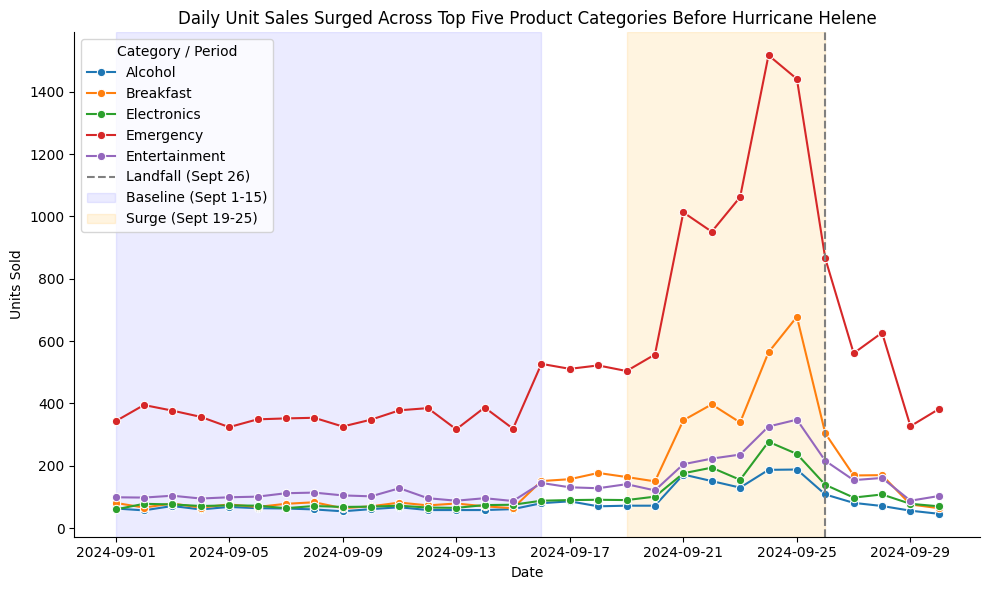

In [42]:
# Q1, Step 6B: Create line chart for absolute daily sales
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=top_daily_sales, x='date', y='units_sold', hue='category', marker='o',ax=ax)

# Mark hurricane landfall
ax.axvline(
    pd.Timestamp('2024-09-26'),
    color='gray',
    linestyle='--',
    label='Landfall (Sept 26)'
)

# Highlight baseline period: September 1–15
ax.axvspan(
    pd.Timestamp('2024-09-01'),
    pd.Timestamp('2024-09-16'),
    color='blue',
    alpha=0.08,
    label='Baseline (Sept 1-15)'
)

# Highlight surge period: September 19–25
ax.axvspan(
    pd.Timestamp('2024-09-19'),
    pd.Timestamp('2024-09-26'),
    color='orange',
    alpha=0.12,
    label='Surge (Sept 19-25)'
)

ax.set_title('Daily Unit Sales Surged Across Top Five Product Categories Before Hurricane Helene')
ax.set_xlabel('Date')
ax.set_ylabel('Units Sold')
ax.set_xticks(pd.date_range('2024-09-01', '2024-09-30', freq='4D'))
ax.legend(title='Category / Period')

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

**Chart Explanation:** This line chart shows the trends in absolute daily unit sales for the top five product categories throughout September 2024, highlighting the baseline and surge periods. Emergency had the highest daily unit sales among the five categories throughout the month. All five categories experienced an increase in daily unit sales during the surge period compared to the baseline period, with sales generally declining after Hurricane Helene made landfall on September 26.

**Code Explanation:** First, we created a line chart with a figure size of (10, 6), using the `top_daily_sales` DataFrame with `date` on the x-axis and `units_sold` on the y-axis. Each line represents one of the top five categories, distinguished by different colors (`hue`), with circular markers at each data point. Then, we marked the hurricane landfall date (Sept 26) in gray, shaded the baseline period (Sept 1-15) in blue, and shaded the surge period (Sept 19-25) in orange. We set the endpoints of the shaded periods to Sept 16 and Sept 26 because the shading stops at 00:00:00 on those dates, ensuring the full intended periods are highlighted. Next, we added the x-axis label, y-axis label, a chart title, and a legend with a title. We set the x-axis ticks to every four days to prevent overlapping date labels. Then, we removed the top and right spines. Finally, we displayed the chart.

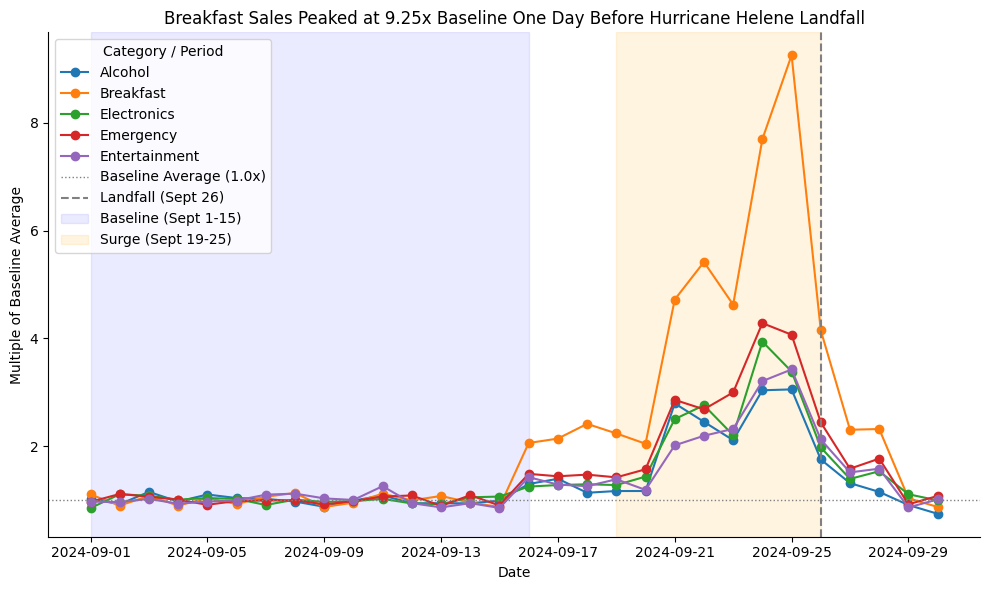

category
Breakfast        9.25
Emergency        4.28
Electronics      3.94
Entertainment    3.43
Alcohol          3.06
dtype: float64


In [43]:
# Q1, Step 7: Compare Daily Sales Relative to Baseline

# Pivot daily sales into wide format
daily_wide = top_daily_sales.pivot(
    index='date',
    columns='category',
    values='units_sold'
)

baseline_avg = daily_wide.loc['2024-09-01':'2024-09-15'].sum() / 15

# Select the top five categories and index their daily sales
# indexed sales = daily units sold / baseline average
indexed = daily_wide / baseline_avg

# Create the line chart for relative daily sales
fig, ax = plt.subplots(figsize=(10, 6))

for category in indexed.columns:
    ax.plot(indexed.index, indexed[category],
            marker='o', label=category)

ax.axhline(1.0, color='gray', linestyle=':', linewidth=1,
           label='Baseline Average (1.0x)')

ax.axvline(pd.Timestamp('2024-09-26'), color='gray',
           linestyle='--', linewidth=1.5,
           label='Landfall (Sept 26)')

# Highlight baseline period: September 1–15
ax.axvspan(
    pd.Timestamp('2024-09-01'),
    pd.Timestamp('2024-09-16'),
    color='blue',
    alpha=0.08,
    label='Baseline (Sept 1-15)'
)

# Highlight surge period: September 19–25
ax.axvspan(
    pd.Timestamp('2024-09-19'),
    pd.Timestamp('2024-09-26'),
    color='orange',
    alpha=0.12,
    label='Surge (Sept 19-25)'
)

ax.set_title('Breakfast Sales Peaked at 9.25x Baseline One Day Before Hurricane Helene Landfall')
ax.set_xlabel('Date')
ax.set_ylabel('Multiple of Baseline Average')
ax.set_xticks(pd.date_range('2024-09-01', '2024-09-30', freq='4D'))

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

ax.legend(title='Category / Period')
plt.tight_layout()
plt.show()

# Identify the peak sales multiple for each category (highest daily sales / baseline average)
print(indexed.max().round(2).sort_values(ascending=False))


**Chart Explanation:** This line chart shows the daily unit sales trends for the top five categories relative to their baseline averages throughout September 2024, highlighting the baseline and surge periods. The horizontal reference line at 1.0x represents the baseline average, with values above 1.0x indicating sales higher than the baseline average and values below 1.0x indicating lower sales. Breakfast had the highest daily sales multiple among the five categories, reaching a peak of 9.25 times its baseline average on September 25, one day before Hurricane Helene made landfall. All five categories experienced increases relative to their baseline averages during the surge period, followed by a decline after landfall.

**Code Explanation:** First, we used `.pivot()` to reshape `top_daily_sales` from long format to wide format, with dates as the index, categories as columns, and daily units sold as values. We stored the results in `daily_wide`. Second, we calculated the average daily units sold for each category during the baseline period (Sept 1-15) from `daily_wide` and stored the result in `baseline_avg`. Third, we divided each category's daily units sold by its baseline average to calculate the daily sales multiples, storing the results in `indexed`. Fourth, we created a line chart showing these multiples for each category, with a horizontal reference line at 1.0 representing the baseline average. Each line represents one of the top five categories, distinguished by different colors (hue), with circular markers at each data point. Then, we marked the hurricane landfall date (Sept 26) in gray, shaded the baseline period (Sept 1-15) in blue, and shaded the surge period (Sept 19-25) in orange. We set the endpoints of the shaded periods to Sept 16 and Sept 26 because the shading stops at 00:00:00 on those dates, ensuring the full intended periods are highlighted. Next, we added the x-axis label, y-axis label, a chart title, and a legend with a title. We set the x-axis ticks to every four days to prevent overlapping date labels. Then, we removed the top and right spines. Finally, we displayed the chart and printed the highest daily sales multiple for each category.

**Written Explanation for Q1:** The top five categories with the highest percentage increases in average daily units sold between baseline period (September 1-15) and surge period (September 19-25) were Breakfast (414.36%), Emergency (184.25%), Electronics (150.27%), Alcohol (125.66%), and Entertainment (124.97%). **Breakfast** experienced the greatest relative sales surge in the 7 days before hurricane landfall compared to the baseline period. Its average daily units sold increased from 73.27 during the baseline period to 376.86 during surge period, representing a 414.36% increase and a surge multiple of 5.14x (376.86 / 73.27). Breakfast also reached a peak of 9.25 times its baseline average on September 25, one day before Hurricane Helene made landfall. Although Emergency had the highest absolute daily unit sales among these categories, Breakfast experienced the largest relative increase. The daily sales trends show that sales increased across all five categories as the hurricane approached, with sales generally declining after landfall.

**Q1 answer, in one sentence a manager could read:** Breakfast experienced the greatest relative sales surge before Hurricane Helene, with average daily sales increasing by 414.36% (5.14x) from the September 1-15 baseline period to the September 19-25 surge period.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [44]:
# TODO
print('unique SKUs before:', transactions['sku'].nunique())
print('unique canoonical products after:', clean_transactions['sku'].nunique())

# Find the largest consolidated family
family_counts = {}

for original in transactions["sku"].dropna().unique():
    canonical = SKU_MAP.get(original, original)
    family_counts[canonical] = family_counts.get(canonical, 0) + 1

largest_count = max(family_counts.values())

for sku, count in family_counts.items():
    if count == largest_count:
        print("Largest consolidated family:", sku)
        print("Number of original SKUs:", count)

unique SKUs before: 45
unique canoonical products after: 20
Largest consolidated family: POPTART-STRAW
Number of original SKUs: 4


**Code Explanation:** First, we counted the number of distinct SKUs before and after consolidation. Second, to find the largest consolidated family, we created an empty dictionary called `family_counts` and used a for loop to go through each unique original SKU, excluding missing values. We used `SKU_MAP.get()` to find the corresponding standardized SKU or keep the original SKU if no mapping existed. We then counted how many original SKUs belonged to each standardized SKU. Finally, we used `max()` to identify the largest family size and another for loop to display the largest consolidated family and its number of original SKUs.

In [45]:
# Prepare data before SKU consolidation
before = transactions.copy()
before = before.drop_duplicates()
before = before[before['quantity'].notna() & (before['quantity'] > 0)].copy()

# Verify SKU consolidation did not change total units
units_before = before['quantity'].sum()
units_after = clean_transactions['quantity'].sum()

assert units_before == units_after, "Total units changed!"

print("Total units before:", units_before)
print("Total units after:", units_after)

Total units before: 49584
Total units after: 49584


**Code Explanation:** First, we prepared the `transactions` data by creating a copy stored in `before` and removing duplicate rows and rows with missing or negative quantities. Second, we summed the `quantity` values in `before` and stored the result in `units_before`, then summed the `quantity` values in `clean_transactions` and stored the result in `units_after`. Third, we used an `assert` statement to check that the total units remained unchanged before and after consolidation. Finally, we printed the total units before and after consolidation.

In [46]:
# Q2, Step 1: Calculate units sold for Pop-Tart after SKU consolidation
poptarts_after = clean_transactions[clean_transactions['sku'] == 'POPTART-STRAW']

poptart_sales_after = (
    poptarts_after.dropna(subset=['date'])
    .groupby(['sku'])['quantity'].sum()
    .reset_index(name='units_sold')
)

poptart_sales_after

,sku,units_sold
0,POPTART-STRAW,5005


**Code Explanation:** First, we filtered `clean_transactions` to select rows with the standardized SKU `POPTART-STRAW` and stored them in `poptarts_after`. Next, we removed rows with missing dates, grouped the data by `sku`, and summed the quantities to calculate the total units sold for Strawberry Pop-Tart after consolidation. We then used `.reset_index(name='units_sold')` to convert the results into a DataFrame with a 'units_sold' column and store the results in `poptarts_sales_after`. Finally, we displayed poptart_sales_after, which shows a total of 5,005 units sold.

In [47]:
# Q2, Step 2: Identify original Pop-Tart SKU variants
poptarts_before = transactions[transactions['product_name'].str.lower().str.contains('pop')].copy()

# Drop duplicates
poptarts_before = poptarts_before.drop_duplicates()

# Normalize timestamps
poptarts_before['timestamp'] = pd.to_datetime(poptarts_before['timestamp'], errors='coerce', format='mixed')

# Create date column
poptarts_before['date'] = poptarts_before['timestamp'].dt.normalize()


# Convert quantity to numeric
poptarts_before['quantity'] = pd.to_numeric(poptarts_before['quantity'], errors='coerce')
# Remove missing and negative quantities
poptarts_before = poptarts_before.dropna(subset=['quantity'])
poptarts_before = poptarts_before[poptarts_before['quantity'] > 0]

# Remove missing dates
poptarts_before = poptarts_before.dropna(subset=['date'])

# Inspect original SKUs
grouped_poptart_sku = poptarts_before.groupby('sku')['product_name'].first()    # one representative product name for each SKU
display(grouped_poptart_sku)
display(poptarts_before[['sku', 'product_name', 'quantity']].head())

,product_name
sku,
POPTART-STRAW,Strawberry Pop-Tart
PT-12,Pop Tarts - Strawberry
PT_STRAWBERRY,pop-tarts strawberry
SKU#459812,POPTART-STRAWBERRY


,sku,product_name,quantity
21,PT_STRAWBERRY,pop-tarts strawberry,4
27,SKU#459812,POPTART-STRAWBERRY,4
29,PT_STRAWBERRY,Strawberry Pop-Tart,3
47,PT-12,Pop Tarts - Strawberry,3
52,POPTART-STRAW,Strawberry Pop-Tart,1


**Code Explanation:** First, we filtered the original `transactions` DataFrame to select rows with product names containing 'pop' after converting them to lowercase. We then created a copy of the filtered data and stored it in `poptarts_before`. Next, we cleaned `poptarts_before` by removing duplicate rows, converting timestamps to datetime format, creating a date column, converting the `quantity` column to numeric values, and removing rows with missing quantities, negative quantities, or missing dates. We then grouped the data by `sku` and selected the first product name for each SKU to identify the original Pop-Tart SKU variants, storing the results in `grouped_poptart_sku`. Finally, we displayed the original SKU variants and the first five rows of `poptarts_before`, showing the `sku`, `product_name`, and `quantity` columns.

In [48]:
# Q2, Step 3: Calculate total units sold before SKU consolidation
poptart_sales_before = (
    poptarts_before.groupby(['sku'])['quantity'].sum()
    .reset_index(name='units_sold')
)
poptart_sales_before

,sku,units_sold
0,POPTART-STRAW,1239
1,PT-12,1332
2,PT_STRAWBERRY,1230
3,SKU#459812,1204


**Code Explanation:** We calculated the total units sold for each original Pop-Tart SKU before consolidation by grouping `poptarts_before` by `sku` and summing the `quantity` values. We then used `.reset_index(name='units_sold')` to convert the results into a DataFrame with a `units_sold` column and stored it in `poptarts_sales_before`. Finally, we displayed `poptart_sales_before`, showing that POPTART-STRAW had 1,239 units sold, PT-12 had 1,332 units sold, PT_STRAWBERRY had 1,230 units sold, and SKU#459812 had 1,204 units sold.

In [49]:
# Q2, Step 4: Verify total units sold before and after
print("Before:", poptart_sales_before['units_sold'].sum())
print("After:", poptart_sales_after['units_sold'].sum())

Before: 5005
After: 5005


**Code Explanation:** We verified the total units sold for Strawberry Pop-Tarts before and after SKU consolidation by summing the `units_sold` column in both DataFrames. Both results show 5,005 units sold, confirming that SKU consolidation did not change the total sales volume.

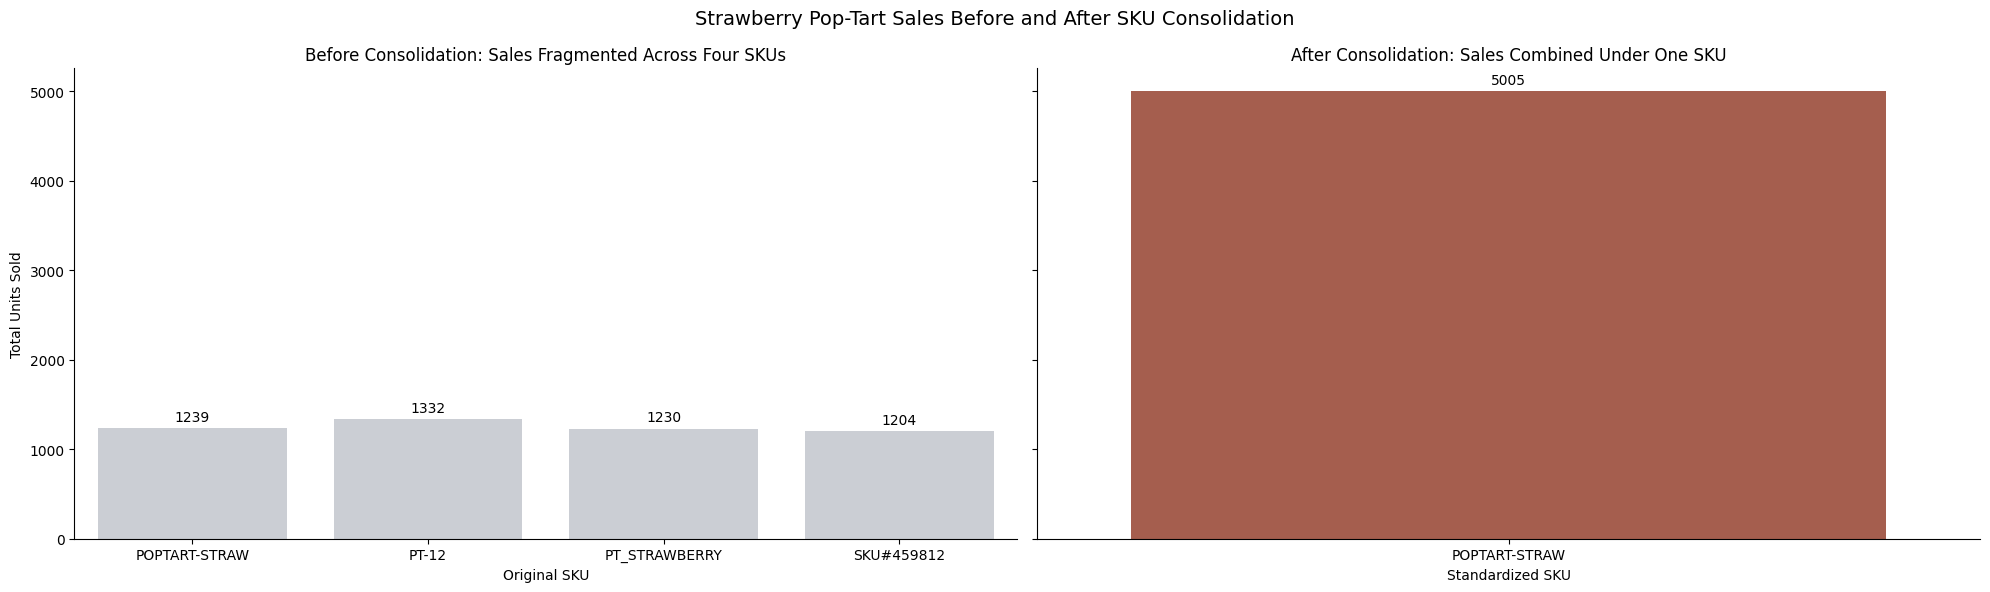

In [50]:
# Q2, Step 5: Create side-by-side bar charts
fig, axes = plt.subplots(ncols=2, figsize=(20,6), sharey=True)
fig.suptitle('Strawberry Pop-Tart Sales Before and After SKU Consolidation', fontsize=14)

# Before SKU consolidation
sns.barplot(data=poptart_sales_before, x='sku', y='units_sold', color='#c9cdd6', ax=axes[0])
axes[0].set_title('Before Consolidation: Sales Fragmented Across Four SKUs')
axes[0].set_xlabel('Original SKU')
axes[0].set_ylabel('Total Units Sold')
axes[0].bar_label(axes[0].containers[0], fmt='%.0f', padding=3)

# After SKU consolidation
sns.barplot(data=poptart_sales_after, x='sku', y='units_sold', color='#b4553f', ax=axes[1])
axes[1].set_title('After Consolidation: Sales Combined Under One SKU')
axes[1].set_xlabel('Standardized SKU')
axes[1].bar_label(axes[1].containers[0], fmt='%.0f', padding=3)

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


**Chart Explanation:** The side-by-side bar charts compare total Strawberry Pop-Tart units sold before and after SKU consolidation. Before consolidation, sales were fragmented across four SKUs (POPTART-STRAW, PT-12, PT_STRAWBERRY, and SKU#459812), each recording approximately 1,200-1,300 units. After consolidation, these four SKUs were combined into a single standardized SKU, POPTART-STRAW, showing a total of 5,005 units sold. This comparison demonstrates how inconsistent SKU naming can misrepresent the overal demand for a product by making one product appear as four different products.

**Code Explanation:** First, we created two side-by-side bar charts with a figure size of (20, 6) and a shared y-axis representing `units_sold` using `sharey=True`. Then, we added an overall figure title using `fig.suptitle()`. For the left chart, we created a bar chart showing the total units sold for each of the four original SKUs on the x-axis, using light gray bars. We added the axis labels, a chart title, and numerical labels above each bar. For the right chart, we created a bar chart showing the total units sold under one standardized SKU on the x-axis, using a reddish-brown bar. We also added axis labels, a chart title, and a numerical label above the bar. Then, we removed the top and right spines from both charts. Finally, we displayed the charts.

In [51]:
# Q2, Step 6: Calculate daily Pop-Tart sales

daily_poptart_sales_after = (
    poptarts_after.dropna(subset=['date'])
    .groupby(['date', 'sku'])['quantity'].sum()
    .reset_index(name='units_sold')
)

daily_poptart_sales_after

,date,sku,units_sold
0,2024-09-01,POPTART-STRAW,81
1,2024-09-02,POPTART-STRAW,66
2,2024-09-03,POPTART-STRAW,79
3,2024-09-04,POPTART-STRAW,66
4,2024-09-05,POPTART-STRAW,76
5,2024-09-06,POPTART-STRAW,68
6,2024-09-07,POPTART-STRAW,78
7,2024-09-08,POPTART-STRAW,83
8,2024-09-09,POPTART-STRAW,64
9,2024-09-10,POPTART-STRAW,70


**Code Explanation:** We calculated the daily units sold for Strawberry Pop-Tarts after SKU consolidation by removing rows with missing dates, grouping `poptarts_after` by `date` and `sku` and summing the `quantity` values. We then used `.reset_index(name='units_sold')` to convert the results into a DataFrame with a `units_sold` column and stored the results in `daily_poptart_sales_after`. Finally, we displayed `daily_poptart_sales_after`, showing the number of units sold each day from 2024-09-01 to 2024-09-30.

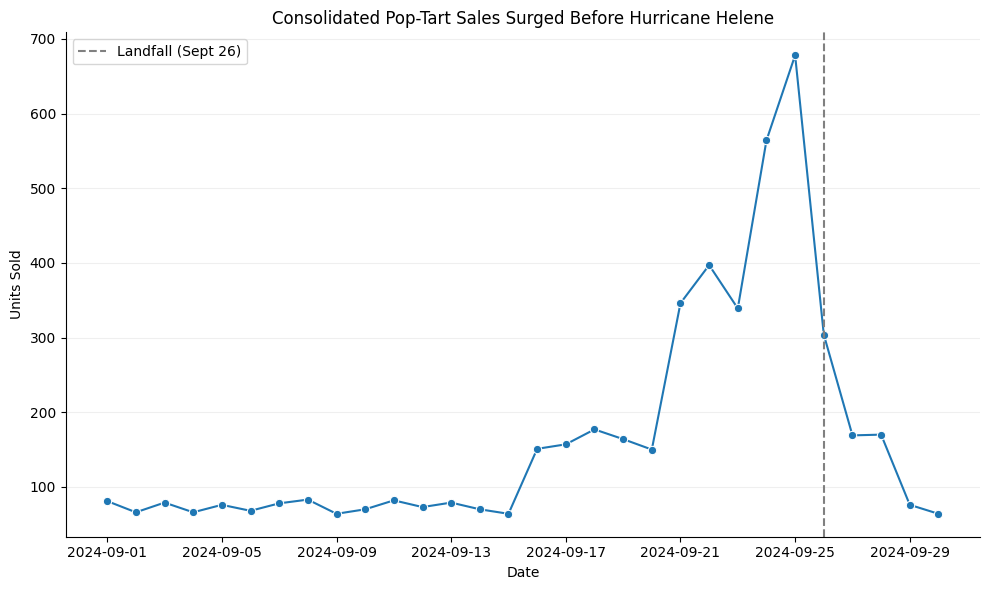

In [52]:
# Q2, Step 7: Create a line chart

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=daily_poptart_sales_after,
    x='date',
    y='units_sold',
    marker='o',
    ax=ax
)

# Mark hurricane landfall
ax.axvline(
    pd.Timestamp('2024-09-26'),
    color='gray',
    linestyle='--',
    label='Landfall (Sept 26)'
)

# Labels and formatting
ax.set_title('Consolidated Pop-Tart Sales Surged Before Hurricane Helene')
ax.set_xlabel('Date')
ax.set_ylabel('Units Sold')

ax.set_xticks(
    pd.date_range('2024-09-01', '2024-10-01', freq='4D')
)

ax.legend()
ax.grid(axis='y', alpha=0.2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

**Chart Explanation:** This line chart shows the true daily sales volume of Strawberry Pop-Tarts after consolidating all Pop-Tart SKU variants into a single standardized product. The dashed gray vertical line marks Hurricane Helene's landfall on September 26, 2024. Daily sales remained relative stable during the baseline period (September 1-15), then increased significantly as the hurricane approached, reaching a peak of 678 units on September 25, one day before landfall. Sales decline sharply after landfall, showing a surge in demand for Strawberry Pop-Tarts ahead of the hurricane.

**Code Explanation:** First, we created a line chart with a figure size of (10, 6), using the `daily_poptart_sales_after` DataFrame with `date` on the x-axis and `units_sold` on the y-axis. Then, we marked the hurricane landfall date (Sept 26) with a dashed gray vertical line. Next, we added the axis labels, a chart title, and a legend identifying the landfall date. We set the x-axis ticks to every four days to prevent overlapping date labels. Then, we added light horizontal gridlines and removed the top and right spines for a cleaner appearance. Finally, we displayed the chart.

**Written Explanation for Q2:** After consolidating all Strawberry Pop-Tart SKU variants into one standardized SKU, the cleaned data showed the true daily sales volume, with demand increasing significantly before Hurricane Helene's landfall and reaching a peak of 678 units on September 25. The side-by-side bar charts compare the uncleaned (fragmented) view and the cleaned (consolidated) view. The fragmented view recorded sales across four different SKUs, while the consolidated view combined these sales under one SKU, showing a total of 5,005 units sold. The fragmented view could make one product appear as four different products, leading to an underestimation of overall demand if each SKU were considered separately. SKU consolidation provided a more accurate picture of the overall demand for Strawberry Pop-Tarts.

The two views could lead to different business decisions, especially in inventory planning, stock allocation, and distribution. Based on the fragmented view, Walmart managers might underestimate the demand for Strawberry Pop-Tarts and order less inventory than needed, potentially leading to stock shortages during the hurricane if they did not realize that the four SKUs represented the same product. In contrast, the consolidated view helps managers better understand the actual demand for Strawberry Pop-Tarts, allowing them to order enough inventory and send more stock to stores experiencing higher demand before the hurricane.

**Q2 answer:** We started with 45 distinct SKUs and ended with 20 canonical products after SKU consolidation. The largest consolidated family was POPTART-STRAW, with four original SKUs combined into one standardized SKU. The side-by-side bar charts compare the uncleaned (fragmented) view and the cleaned (consolidated) view. The fragmented view recorded sales across four different SKUs (POPTART-STRAW, PT-12, PT_STRAWBERRY, and SKU#459812), each recording approximately 1,200-1,300 units sold. The consolidated view combined these sales under one SKU, showing a total of 5,005 units sold. After removing duplicate transactions and negative quantities, the total units sold remained unchanged at 49,584 before and after SKU consolidation, confirming that the overall sales volume was preserved.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [53]:
# TODO

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [54]:
progress = {
    'q1_multiple': 5.14,            # TODO: a number
    'q1_baseline_window': 'September 1-15, 2024',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': None, # TODO: True/False
    'q3_days_in_correlation': None, # TODO: a number
    'charts_with_message_titles': 6,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.14
PASS - q1_baseline_window = September 1-15, 2024
PASS - q2_canonical_products = 20
FAIL - q3_join_rows_preserved = None
FAIL - q3_days_in_correlation = None
PASS - charts_with_message_titles = 6
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a) One finding that surprised our team was that the breakfast category experienced the greatest percentage increase in sales (414.36%) during the surge period, even though the emergency category had the highest absolute daily sales among the top five categories. To verify whether this finding was real rather than a bug, we checked our calculations of average daily sales for the baseline and surge periods and used the indexed daily sales chart to compare sales relative to each category's baseline average. These checks confirmed that breakfast experienced the largest relative increase and that the finding was not caused by a calculation error.

b) We are least confident in the 124.97% sales increase for the entertainment category from the baseline period (September 1-15) to the surge period (September 19-25). Q5 states that the board games/entertainment category shows a +250% sales increase, which is substantially higher than our calculated result. We used September 1-15 as the baseline period to represent normal demand before the hurricane and cleaned the data by standardizing product categories, removing duplicate rows, and excluding rows with negative quantities and missing dates for our analysis. These decisions may explain why our calculated percentage differs from the 250% stated in Q5.
Therefore, we are less confident in whether our calculated 124.97% increase accurately reflects the actual change in entertainment sales.